# Plot Multiple-Seed Matrix Factorization Results

Load the saved averaged histories and recreate the original plots without rerunning all seeds.

In [14]:
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
from utils import plot_figures, plot_for_paper_2, plot_for_paper_penalty

In [15]:
DATA_FILE = Path("mf_results_multiple.pkl")
if not DATA_FILE.exists():
    DATA_FILE = Path("MF") / DATA_FILE
with DATA_FILE.open("rb") as result_file:
    results = pickle.load(result_file)
histories = results["histories"]
labels = [label for label in results["labels"] if label != "LeAP-SSN"]
history_list = [histories[label] for label in labels]
print(f"Loaded {len(history_list)} averaged histories from {DATA_FILE}")

Loaded 6 averaged histories from mf_results_multiple.pkl


In [16]:
line_widths = [2.5] * len(labels)
line_styles = ["-"] * len(labels)
colors = ["#E8601C", "#9B8AC4", "#88A5DD", "#8DCBE4", "#C2E3D2", "#DDECBF"]
marker_cycle = ["None", "s", "^", "D", "x", "v"]
mn_func = min(np.min(history["func"]) for history in history_list)

last func residual of Gradient Method: 0.016364201986454496
last func residual of GLAd-SSN, p=0.2: 0.00015360883068815667
last func residual of GLAd-SSN, p=0.4: 0.001269935791186505
last func residual of GLAd-SSN, p=0.5: 0.0012104463489075457
last func residual of GLAd-SSN, p=0.6: 0.0055607550640806025
last func residual of GLAd-SSN, p=0.8: 0.0
last func residual of Gradient Method: 0.0004395148786187529
last func residual of GLAd-SSN, p=0.2: 1.6075134791466285e-06
last func residual of GLAd-SSN, p=0.4: 2.3179015946812685e-06
last func residual of GLAd-SSN, p=0.5: 2.390902261238756e-07
last func residual of GLAd-SSN, p=0.6: 0.0006619709921501474
last func residual of GLAd-SSN, p=0.8: 2.282045628572906e-05


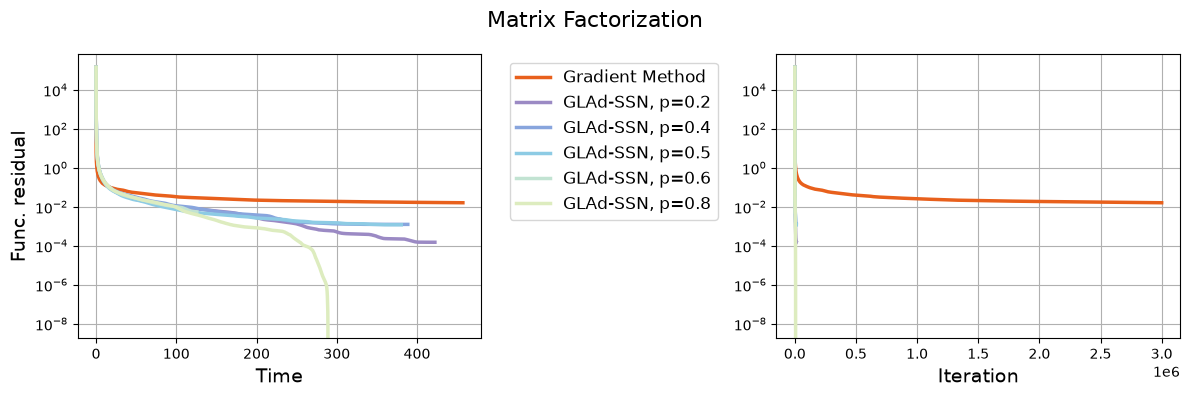

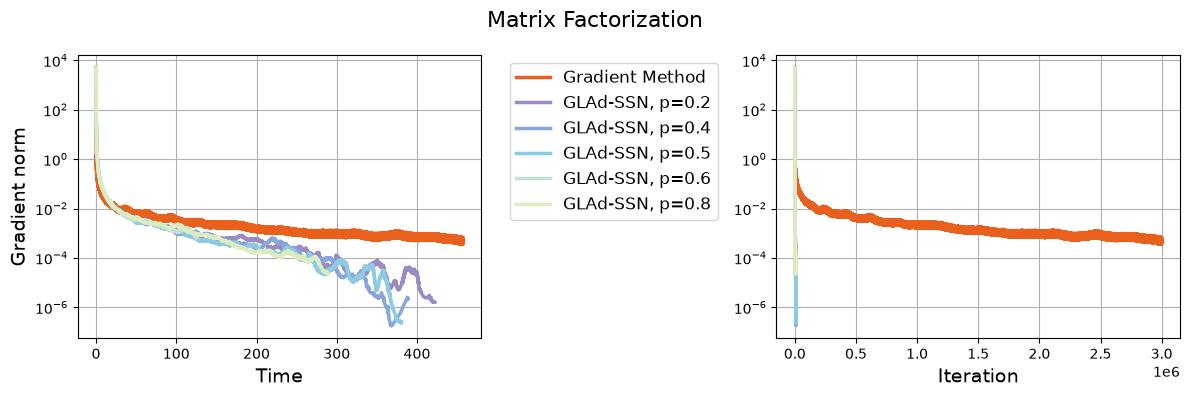

In [17]:
plot_figures(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=mn_func, threshold=1e-10, suptitle="Matrix Factorization", which_measure_2="func", max_iter=1000)
plot_figures(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=0, threshold=1e-10, suptitle="Matrix Factorization", max_iter=1000, which_measure_1="grad_norm", which_measure_2="grad_norm", ylabel="Gradient norm")

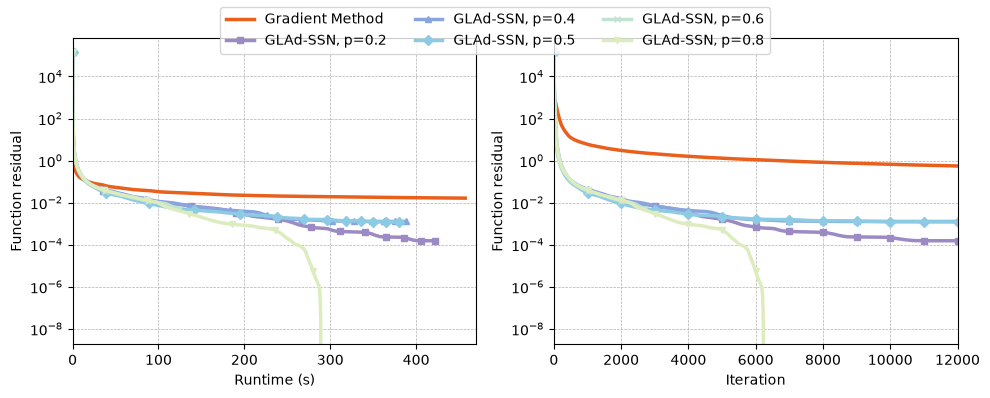

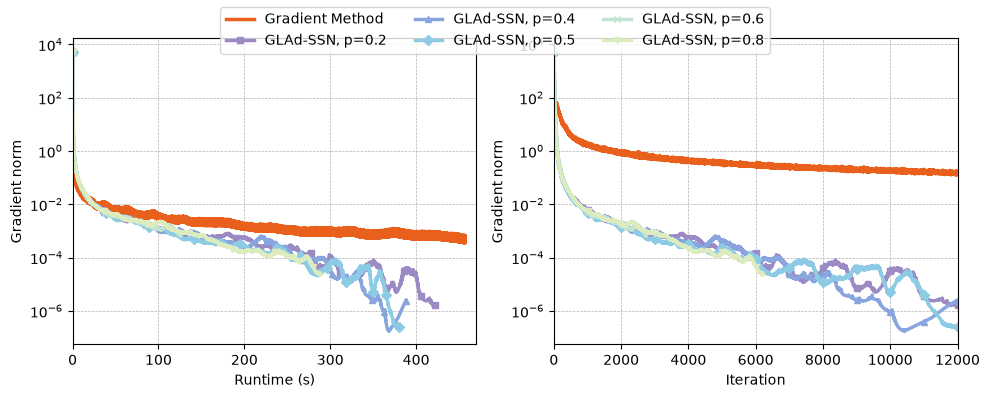

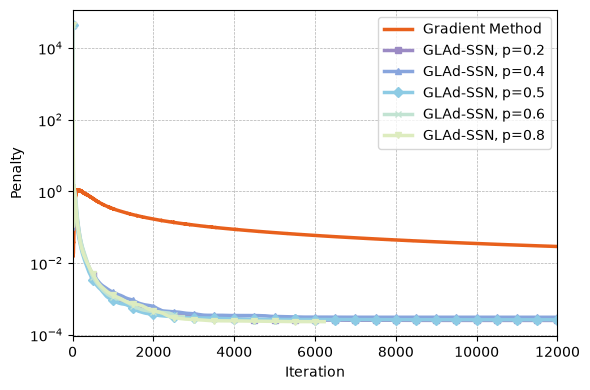

In [18]:
markevery_numbers = [50000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
plot_for_paper_2(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=mn_func, threshold=1e-10, suptitle="Plots", max_iter=12000, which_measure="func", marker_cycle=marker_cycle, markevery_numbers=markevery_numbers)
plot_for_paper_2(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=mn_func, threshold=1e-10, suptitle="Plots", max_iter=12000, which_measure="grad_norm", marker_cycle=marker_cycle, markevery_numbers=markevery_numbers)
plot_for_paper_penalty(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, marker_cycle=marker_cycle, max_time=12000)

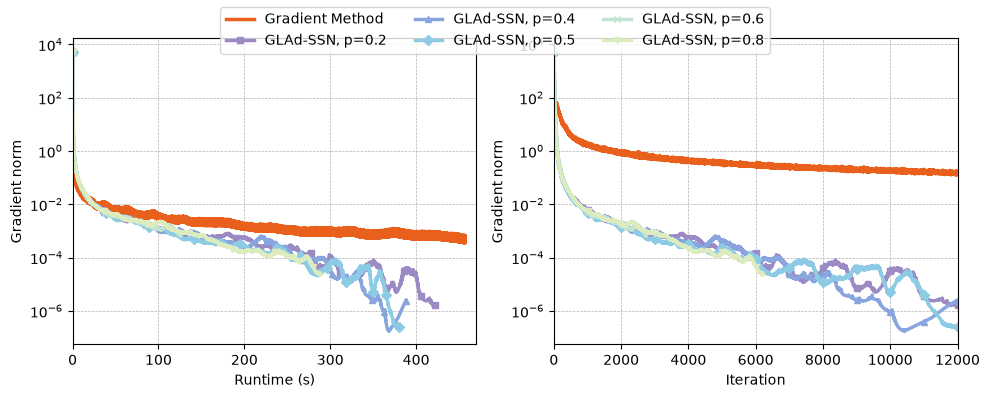

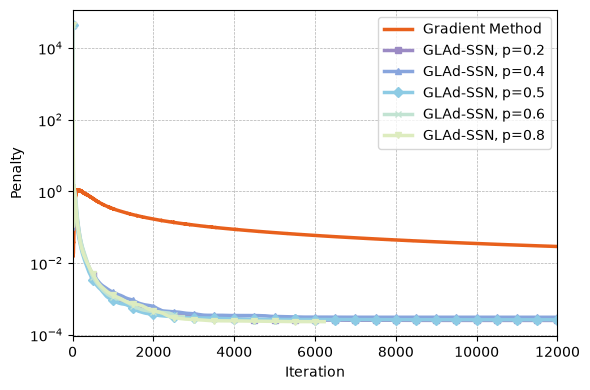

In [19]:
# Save the last two figures as PDFs.
plot_for_paper_2(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, n=100, m=None, mu_str="0.5", f_star=mn_func, threshold=1e-10, suptitle="Plots", max_iter=12000, which_measure="grad_norm", marker_cycle=marker_cycle, markevery_numbers=markevery_numbers)
plot_for_paper_penalty(history_list, labels, colors=colors, linewidths=line_widths, linestyles=line_styles, marker_cycle=marker_cycle, max_time=12000, filename="plot_MF_penalty.pdf")